### Data loading and train/validation split

Load the train and test splits, run basic checks, and make the 80/20 stratified split that all three models will share.

In [3]:
import sys

from sklearn.model_selection import train_test_split

# let the notebook import from src/
sys.path.append("../src")
from load_data import load_split, load_sample_submission

In [4]:
# load the train split
cells, rna, protein, labels = load_split("train")

# load the two test splits (they have no labels)
test1_cells, test1_rna, test1_protein, test1_labels = load_split("test1")
test2_cells, test2_rna, test2_protein, test2_labels = load_split("test2")

# load the example submission
sample_submission = load_sample_submission()

In [48]:
# print the shapes of each file
print("train cells: ", cells.shape)
print("train rna: ", rna.shape)
print("train protein:", protein.shape)
print("train labels: ", labels.shape)
print()
print("test1 cells: ", test1_cells.shape)
print("test1 rna: ", test1_rna.shape)
print("test1 protein:", test1_protein.shape)
print()
print("test2 cells: ", test2_cells.shape)
print("test2 rna: ", test2_rna.shape)
print("test2 protein:", test2_protein.shape)
print()
print("sample submission:", sample_submission.shape)
print(sample_submission.columns)

train cells:  (7000, 8)
train rna:  (7000, 3000)
train protein: (7000, 217)
train labels:  (7000, 2)

test1 cells:  (1500, 6)
test1 rna:  (1500, 3000)
test1 protein: (1500, 217)

test2 cells:  (1500, 6)
test2 rna:  (1500, 3000)
test2 protein: (1500, 217)

sample submission: (3000, 2)
Index(['ID', 'label'], dtype='str')


In [6]:
# look at the first few rows of the metadata
cells.head()

,cell_id,cell_type,cell_type_original,n_genes_by_counts,total_counts,pct_counts_mt,donor,time
0,E2L6_TTCTTGATCGTTCTCG,B,B,1843,5962.0,8.352901,P5,7
1,L1_AGGCTGCAGACCTCCG,B,B,730,1205.0,11.037345,P4,3
2,E2L7_GTTAGACAGTAATCCC,B,B,2223,7775.0,6.893890,P6,3
3,E2L1_ACCGTTCGTACGATGG,B,B,1719,5781.0,7.922505,P5,0
4,E2L7_GTGGGAATCTATCGTT,B,B,1551,5735.0,7.689625,P7,3


In [7]:
# count the cells in each cell type
print(labels["cell_type"].value_counts())

cell_type
Mono     2353
CD4 T    2006
CD8 T    1217
NK        767
B         657
Name: count, dtype: int64


### 80/20 stratified split

Split row positions (0 to 6999), so the same rows can be used for RNA, protein, and labels, and all three models get exactly the same split.

In [8]:
# make a list of row positions, one per cell
row_positions = []
for position in range(len(labels)):
    row_positions.append(position)

# the target for each cell
cell_types = labels["cell_type"].values

# split the row positions 80/20, keeping cell type proportions the same
train_rows, valid_rows = train_test_split(
    row_positions,
    test_size=0.2,
    stratify=cell_types,
    random_state=42,
)

print("train part:", len(train_rows))
print("valid part:", len(valid_rows))

train part: 5600
valid part: 1400


In [ ]:
# pick out the labels for each part
train_labels = cell_types[train_rows]
valid_labels = cell_types[valid_rows]

# pick out the RNA rows for each part
train_rna = rna[train_rows]
valid_rna = rna[valid_rows]

# pick out the protein rows for each part
train_protein = protein.iloc[train_rows]
valid_protein = protein.iloc[valid_rows]

print("train rna:", train_rna.shape)
print("valid rna:", valid_rna.shape)
print("train protein:", train_protein.shape)
print("valid protein:", valid_protein.shape)

train rna:     (5600, 3000)
valid rna:     (1400, 3000)
train protein: (5600, 217)
valid protein: (1400, 217)


In [10]:
# check that the cell type proportions are similar in both parts
train_label_counts = labels["cell_type"].iloc[train_rows].value_counts(normalize=True)
valid_label_counts = labels["cell_type"].iloc[valid_rows].value_counts(normalize=True)

print("train proportions:")
print(train_label_counts.round(3))
print()
print("valid proportions:")
print(valid_label_counts.round(3))

train proportions:
cell_type
Mono     0.336
CD4 T    0.287
CD8 T    0.174
NK       0.110
B        0.094
Name: proportion, dtype: float64

valid proportions:
cell_type
Mono     0.336
CD4 T    0.286
CD8 T    0.174
NK       0.109
B        0.094
Name: proportion, dtype: float64


Note: Everything before this point can be copy and pasted into our other models


### Protein-only logistic regression

Scale the protein features (fit on the training part only), train a logistic regression, and score it on the validation set

In [11]:
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [12]:
# fit the scaler on the training part only
protein_scaler = StandardScaler()
protein_scaler.fit(train_protein)

# apply the same scaling to both parts
train_protein_scaled = protein_scaler.transform(train_protein)
valid_protein_scaled = protein_scaler.transform(valid_protein)

print("train protein scaled:", train_protein_scaled.shape)
print("valid protein scaled:", valid_protein_scaled.shape)

train protein scaled: (5600, 217)
valid protein scaled: (1400, 217)


In [49]:
# make the logistic regression model
protein_model = LogisticRegression(max_iter=1000, random_state=42)

# train it on the training part
protein_model.fit(train_protein_scaled, train_labels)

print("classes:", protein_model.classes_)

classes: ['B' 'CD4 T' 'CD8 T' 'Mono' 'NK']


In [14]:
# predict the validation cells
valid_predictions = protein_model.predict(valid_protein_scaled)

# overall scores
protein_accuracy = accuracy_score(valid_labels, valid_predictions)
protein_macro_f1 = f1_score(valid_labels, valid_predictions, average="macro")

print("accuracy:", round(protein_accuracy, 4))
print("macro F1:", round(protein_macro_f1, 4))

accuracy: 0.9979
macro F1: 0.998


In [15]:
# precision, recall, and F1 for each cell type
print(classification_report(valid_labels, valid_predictions, digits=3))

              precision    recall  f1-score   support

           B      1.000     1.000     1.000       131
       CD4 T      0.993     1.000     0.996       401
       CD8 T      1.000     0.988     0.994       244
        Mono      1.000     1.000     1.000       471
          NK      1.000     1.000     1.000       153

    accuracy                          0.998      1400
   macro avg      0.999     0.998     0.998      1400
weighted avg      0.998     0.998     0.998      1400



In [16]:
# confusion matrix: rows are the true type, columns are the predicted type
protein_confusion = confusion_matrix(valid_labels, valid_predictions, labels=protein_model.classes_)

# put it in a table with the cell type names
protein_confusion_table = pd.DataFrame(
    protein_confusion,
    index=protein_model.classes_,
    columns=protein_model.classes_,
)
protein_confusion_table

,B,CD4 T,CD8 T,Mono,NK
B,131,0,0,0,0
CD4 T,0,401,0,0,0
CD8 T,0,3,241,0,0
Mono,0,0,0,471,0
NK,0,0,0,0,153


### Checking for leakage

If the code is leaking the answer, the model will still score high even with random labels. We shuffle the training labels, train the same model, and score it on the real validation labels

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [50]:
# shuffle the training labels so they no longer match the cells
random_generator = np.random.default_rng(42)
shuffled_train_labels = random_generator.permutation(train_labels)

# train the same model on the shuffled labels
shuffled_model = LogisticRegression(max_iter=1000, random_state=42)
shuffled_model.fit(train_protein_scaled, shuffled_train_labels)

# score it on the real validation labels
shuffled_predictions = shuffled_model.predict(valid_protein_scaled)
shuffled_accuracy = accuracy_score(valid_labels, shuffled_predictions)

# accuracy from always guessing the most common type
most_common_type = pd.Series(train_labels).value_counts().index[0]
guess_accuracy = np.mean(valid_labels == most_common_type)

print("real labels: ", round(protein_accuracy, 3))
print("shuffled labels: ", round(shuffled_accuracy, 3))
print("always guess", most_common_type + ":", round(guess_accuracy, 3))

real labels:  0.998
shuffled labels:  0.284
always guess Mono: 0.336


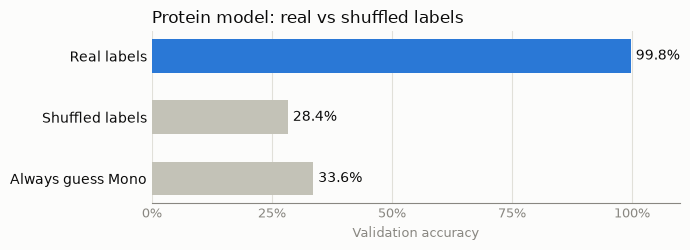

In [51]:
# chart colors
surface_color = "#fcfcfb"
highlight_color = "#2a78d6"
context_color = "#c3c2b7"
text_color = "#0b0b0b"
muted_color = "#898781"
grid_color = "#e1e0d9"

# bar names, values, and colors (top bar first)
bar_names = ["Real labels", "Shuffled labels", "Always guess " + most_common_type]
bar_values = [protein_accuracy, shuffled_accuracy, guess_accuracy]
bar_colors = [highlight_color, context_color, context_color]

figure, axis = plt.subplots(figsize=(7, 2.6))
figure.patch.set_facecolor(surface_color)
axis.set_facecolor(surface_color)

# draw the bars and write each value past the end of its bar
for position in range(len(bar_names)):
    axis.barh(position, bar_values[position], height=0.55, color=bar_colors[position])
    label = str(round(bar_values[position] * 100, 1)) + "%"
    axis.text(bar_values[position] + 0.01, position, label, va="center", fontsize=10, color=text_color)

# put the first bar on top
axis.set_yticks(range(len(bar_names)))
axis.set_yticklabels(bar_names, fontsize=10, color=text_color)
axis.invert_yaxis()

# percent axis from 0 to 100
axis.set_xlim(0, 1.1)
axis.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
axis.set_xticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=9, color=muted_color)
axis.set_xlabel("Validation accuracy", fontsize=9, color=muted_color)

# light vertical grid, no box
axis.grid(axis="x", color=grid_color, linewidth=0.8)
axis.set_axisbelow(True)
for side in ["top", "right", "left"]:
    axis.spines[side].set_visible(False)
axis.spines["bottom"].set_color(muted_color)
axis.tick_params(axis="both", length=0)

axis.set_title("Protein model: real vs shuffled labels", loc="left", fontsize=12, color=text_color)
plt.tight_layout()
plt.show()

### Marker proteins by cell type

Why does protein work so well? Immunologists define these 5 cell types by a few surface proteins. This table shows the average CLR value of those marker proteins in each cell type (all 7,000 training cells, for description only, not used by the model).

In [52]:
# classic marker proteins for each cell type
marker_proteins = ["CD3", "CD4", "CD8", "CD19", "CD20", "CD14", "CD56", "CD16"]

# keep only the marker columns and add the cell type
marker_values = protein[marker_proteins].copy()
marker_values["cell_type"] = cell_types

# average value of each marker in each cell type
marker_table = marker_values.groupby("cell_type").mean()
marker_table.round(2)

,CD3,CD4,CD8,CD19,CD20,CD14,CD56,CD16
cell_type,,,,,,,,
B,0.98,2.68,-0.18,3.94,1.04,-0.05,0.10,0.56
CD4 T,3.23,5.65,0.06,0.71,-1.29,0.15,0.67,0.61
CD8 T,3.06,2.80,3.17,0.71,-1.25,0.08,0.50,0.67
Mono,0.97,3.64,-0.22,0.59,-1.55,1.41,0.16,0.76
NK,1.15,2.82,0.75,0.74,-1.26,0.08,2.05,2.91


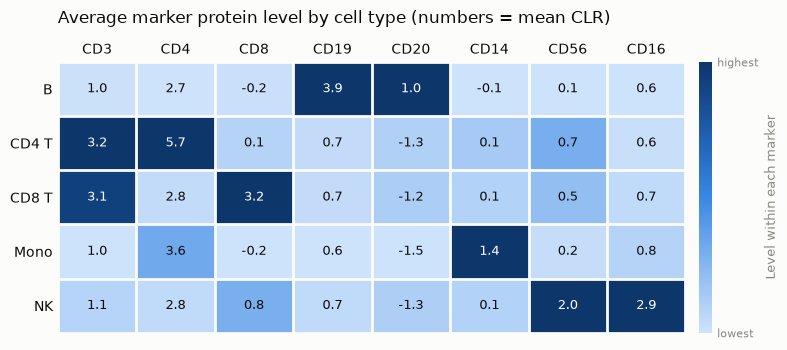

In [53]:
# scale each marker from 0 (lowest cell type) to 1 (highest cell type)
relative_table = marker_table.copy()
for marker in marker_proteins:
    column_values = marker_table[marker]
    lowest = column_values.min()
    highest = column_values.max()
    relative_table[marker] = (column_values - lowest) / (highest - lowest)

# one-hue blue scale, light = low, dark = high
blue_steps = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
blue_scale = LinearSegmentedColormap.from_list("blues", blue_steps)

figure, axis = plt.subplots(figsize=(8, 3.6))
figure.patch.set_facecolor(surface_color)
image = axis.imshow(relative_table.values, cmap=blue_scale, aspect="auto", vmin=0, vmax=1)

# write the real average inside each square
for row in range(marker_table.shape[0]):
    for column in range(marker_table.shape[1]):
        value = marker_table.values[row, column]
        # white text on dark squares, dark text on light squares
        if relative_table.values[row, column] > 0.5:
            square_text_color = "#ffffff"
        else:
            square_text_color = text_color
        axis.text(column, row, str(round(value, 1)), ha="center", va="center", fontsize=9, color=square_text_color)

# label the rows and columns
axis.set_xticks(range(len(marker_proteins)))
axis.set_xticklabels(marker_proteins, fontsize=10, color=text_color)
axis.set_yticks(range(len(marker_table.index)))
axis.set_yticklabels(marker_table.index, fontsize=10, color=text_color)
axis.xaxis.tick_top()
axis.tick_params(axis="both", length=0)

# thin gaps between squares, no box
axis.set_xticks(np.arange(-0.5, len(marker_proteins), 1), minor=True)
axis.set_yticks(np.arange(-0.5, len(marker_table.index), 1), minor=True)
axis.grid(which="minor", color=surface_color, linewidth=2)
axis.tick_params(which="minor", length=0)
for side in ["top", "right", "left", "bottom"]:
    axis.spines[side].set_visible(False)

# color scale legend
color_bar = figure.colorbar(image, ax=axis, fraction=0.04, pad=0.02)
color_bar.set_label("Level within each marker", fontsize=9, color=muted_color)
color_bar.set_ticks([0, 1])
color_bar.set_ticklabels(["lowest", "highest"])
color_bar.outline.set_visible(False)
color_bar.ax.tick_params(labelsize=8, colors=muted_color, length=0)

axis.set_title("Average marker protein level by cell type (numbers = mean CLR)", loc="left", fontsize=12, color=text_color, pad=28)
plt.tight_layout()
plt.show()

Each column is one marker, colored from the cell type with the lowest average (light) to the highest (dark). The numbers are the real average CLR values. Each cell type should have its own dark block: CD3 for both T cells, CD4 for CD4 T, CD8 for CD8 T, CD19/CD20 for B, CD14 for Mono, CD56/CD16 for NK.

### RNA-only logistic regression

Same steps and same settings as the protein model, so the only thing that changes is the input data. Beacuse the RNA matrix is sparse, we turn it into a regular array first

In [54]:
# turn the sparse RNA matrices into regular (dense) arrays
train_rna_dense = train_rna.toarray()
valid_rna_dense = valid_rna.toarray()

# fit the scaler on the training part only
rna_scaler = StandardScaler()
rna_scaler.fit(train_rna_dense)

# apply the same scaling to both parts
train_rna_scaled = rna_scaler.transform(train_rna_dense)
valid_rna_scaled = rna_scaler.transform(valid_rna_dense)

print("train rna scaled:", train_rna_scaled.shape)
print("valid rna scaled:", valid_rna_scaled.shape)

train rna scaled: (5600, 3000)
valid rna scaled: (1400, 3000)


In [23]:
# make the logistic regression model (same settings as protein)
rna_model = LogisticRegression(max_iter=1000, random_state=42)

# train it on the training part
rna_model.fit(train_rna_scaled, train_labels)

print("classes:", rna_model.classes_)

classes: ['B' 'CD4 T' 'CD8 T' 'Mono' 'NK']


In [24]:
# predict the validation cells
rna_valid_predictions = rna_model.predict(valid_rna_scaled)

# overall scores
rna_accuracy = accuracy_score(valid_labels, rna_valid_predictions)
rna_macro_f1 = f1_score(valid_labels, rna_valid_predictions, average="macro")

# count the wrong cells for both models
rna_wrong = np.sum(rna_valid_predictions != valid_labels)
protein_wrong = np.sum(valid_predictions != valid_labels)

print("accuracy:", round(rna_accuracy, 4))
print("macro F1:", round(rna_macro_f1, 4))
print("wrong cells:", rna_wrong, "out of", len(valid_labels))

accuracy: 0.9857
macro F1: 0.9848
wrong cells: 20 out of 1400


In [25]:
# precision, recall, and F1 for each cell type
print(classification_report(valid_labels, rna_valid_predictions, digits=3))

              precision    recall  f1-score   support

           B      1.000     1.000     1.000       131
       CD4 T      0.966     0.995     0.980       401
       CD8 T      0.991     0.930     0.960       244
        Mono      1.000     1.000     1.000       471
          NK      0.974     0.993     0.984       153

    accuracy                          0.986      1400
   macro avg      0.986     0.984     0.985      1400
weighted avg      0.986     0.986     0.986      1400



In [26]:
# confusion matrix: rows are the true type, columns are the predicted type
rna_confusion = confusion_matrix(valid_labels, rna_valid_predictions, labels=rna_model.classes_)

# put it in a table with the cell type names
rna_confusion_table = pd.DataFrame(
    rna_confusion,
    index=rna_model.classes_,
    columns=rna_model.classes_,
)
rna_confusion_table

,B,CD4 T,CD8 T,Mono,NK
B,131,0,0,0,0
CD4 T,0,399,1,0,1
CD8 T,0,14,227,0,3
Mono,0,0,0,471,0
NK,0,0,1,0,152


### Protein vs RNA so far

In [55]:
# put the protein and RNA scores side by side
comparison_table = pd.DataFrame(
    {
        "accuracy": [protein_accuracy, rna_accuracy],
        "macro F1": [protein_macro_f1, rna_macro_f1],
        "wrong cells": [protein_wrong, rna_wrong],
    },
    index=["protein-only", "RNA-only"],
)
comparison_table.round(4)

,accuracy,macro F1,wrong cells
protein-only,0.9979,0.9980,3
RNA-only,0.9857,0.9848,20


### Combined (RNA + protein) logistic regression

Each cell gets its 3,000 scaled RNA values and its 217 scaled protein values side by side (3,217 total). The scalers were already fit on the training part only, and scaling works one column at a time, so joining the scaled parts is the same as scaling the joined data.

In [28]:
# put the scaled RNA and scaled protein side by side for each cell
train_combined = np.hstack([train_rna_scaled, train_protein_scaled])
valid_combined = np.hstack([valid_rna_scaled, valid_protein_scaled])

print("train combined:", train_combined.shape)
print("valid combined:", valid_combined.shape)

train combined: (5600, 3217)
valid combined: (1400, 3217)


In [29]:
# make the logistic regression model (same settings as the others)
combined_model = LogisticRegression(max_iter=1000, random_state=42)

# train it on the training part
combined_model.fit(train_combined, train_labels)

print("classes:", combined_model.classes_)

classes: ['B' 'CD4 T' 'CD8 T' 'Mono' 'NK']


In [56]:
# predict the validation cells
combined_valid_predictions = combined_model.predict(valid_combined)

# overall scores
combined_accuracy = accuracy_score(valid_labels, combined_valid_predictions)
combined_macro_f1 = f1_score(valid_labels, combined_valid_predictions, average="macro")
combined_wrong = np.sum(combined_valid_predictions != valid_labels)

print("accuracy:", round(combined_accuracy, 4))
print("macro F1:", round(combined_macro_f1, 4))
print("wrong cells:", combined_wrong, "out of", len(valid_labels))

accuracy: 0.9964
macro F1: 0.9957
wrong cells: 5 out of 1400


In [31]:
# precision, recall, and F1 for each cell type
print(classification_report(valid_labels, combined_valid_predictions, digits=3))

              precision    recall  f1-score   support

           B      1.000     1.000     1.000       131
       CD4 T      0.995     0.998     0.996       401
       CD8 T      1.000     0.984     0.992       244
        Mono      1.000     1.000     1.000       471
          NK      0.981     1.000     0.990       153

    accuracy                          0.996      1400
   macro avg      0.995     0.996     0.996      1400
weighted avg      0.996     0.996     0.996      1400



In [32]:
# confusion matrix: rows are the true type, columns are the predicted type
combined_confusion = confusion_matrix(valid_labels, combined_valid_predictions, labels=combined_model.classes_)

# put it in a table with the cell type names
combined_confusion_table = pd.DataFrame(
    combined_confusion,
    index=combined_model.classes_,
    columns=combined_model.classes_,
)
combined_confusion_table

,B,CD4 T,CD8 T,Mono,NK
B,131,0,0,0,0
CD4 T,0,400,0,0,1
CD8 T,0,2,240,0,2
Mono,0,0,0,471,0
NK,0,0,0,0,153


### All three models: train vs validation

The validation cells were never used for training, so they act as our local test set (the real test sets have no labels). If a model scores much higher on its training cells than on validation, it is overfitting.

In [33]:
# accuracy on the cells each model was trained on
protein_train_accuracy = protein_model.score(train_protein_scaled, train_labels)
rna_train_accuracy = rna_model.score(train_rna_scaled, train_labels)
combined_train_accuracy = combined_model.score(train_combined, train_labels)

# all three models side by side
final_table = pd.DataFrame(
    {
        "train accuracy": [protein_train_accuracy, rna_train_accuracy, combined_train_accuracy],
        "valid accuracy": [protein_accuracy, rna_accuracy, combined_accuracy],
        "valid macro F1": [protein_macro_f1, rna_macro_f1, combined_macro_f1],
        "valid wrong cells": [protein_wrong, rna_wrong, combined_wrong],
    },
    index=["protein-only", "RNA-only", "combined"],
)

# gap between train and valid accuracy (bigger gap = more overfitting)
final_table["gap"] = final_table["train accuracy"] - final_table["valid accuracy"]
final_table.round(4)

,train accuracy,valid accuracy,valid macro F1,valid wrong cells,gap
protein-only,1.0,0.9979,0.9980,3,0.0021
RNA-only,1.0,0.9857,0.9848,20,0.0143
combined,1.0,0.9964,0.9957,5,0.0036


### 5-fold cross-validation

One 80/20 split gives each model only one score, and a difference of 2–3 cells could just be luck. Cross-validation splits all 7,000 training cells into 5 equal parts (folds). Each fold takes a turn as the validation part while the other 4 are used for training, so every model gets 5 scores.

- All three models use the same 5 folds so the comparison stays fair
- The scaler is fit inside each fold on just the fold's training part
- We use the same settings as before (`C=1.0`), and the helper function below just repeats our scale -> train -> score steps

In [34]:
from sklearn.model_selection import StratifiedKFold


def fit_and_score(train_features, train_labels, valid_features, valid_labels, c_value):
    """Scale, train a logistic regression, and score it on the validation part."""
    # fit the scaler on the training part only
    scaler = StandardScaler()
    scaler.fit(train_features)
    train_scaled = scaler.transform(train_features)
    valid_scaled = scaler.transform(valid_features)

    # train the model
    model = LogisticRegression(C=c_value, max_iter=1000, random_state=42)
    model.fit(train_scaled, train_labels)

    # score it on the validation part
    predictions = model.predict(valid_scaled)
    accuracy = accuracy_score(valid_labels, predictions)
    macro_f1 = f1_score(valid_labels, predictions, average="macro")
    wrong = np.sum(predictions != valid_labels)
    return accuracy, macro_f1, wrong

In [35]:
# all 7,000 cells as regular arrays
all_rna = rna.toarray()
all_protein = protein.values
all_combined = np.hstack([all_rna, all_protein])

# the three feature sets to compare
feature_sets = {
    "protein-only": all_protein,
    "RNA-only": all_rna,
    "combined": all_combined,
}

for model_name in feature_sets:
    print(model_name, feature_sets[model_name].shape)

protein-only (7000, 217)
RNA-only (7000, 3000)
combined (7000, 3217)


In [36]:
# 5 folds, keeping cell type proportions the same in each
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# one row per model per fold
cv_rows = []
fold_number = 0
for cv_train_rows, cv_valid_rows in folds.split(all_protein, cell_types):
    fold_number = fold_number + 1

    # train and score each model on this fold
    for model_name in feature_sets:
        features = feature_sets[model_name]
        accuracy, macro_f1, wrong = fit_and_score(
            features[cv_train_rows],
            cell_types[cv_train_rows],
            features[cv_valid_rows],
            cell_types[cv_valid_rows],
            c_value=1.0,
        )
        cv_rows.append({
            "model": model_name,
            "fold": fold_number,
            "accuracy": accuracy,
            "macro F1": macro_f1,
            "wrong cells": wrong,
        })

    print("finished fold", fold_number)

# turn the results into a table
cv_results = pd.DataFrame(cv_rows)
cv_results

finished fold 1
finished fold 2
finished fold 3
finished fold 4
finished fold 5


,model,fold,accuracy,macro F1,wrong cells
0,protein-only,1,0.997143,0.996048,4
1,RNA-only,1,0.979286,0.978374,29
2,combined,1,0.995714,0.993998,6
3,protein-only,2,0.998571,0.998276,2
4,RNA-only,2,0.991429,0.990852,12
5,combined,2,0.999286,0.998936,1
6,protein-only,3,0.996429,0.995941,5
7,RNA-only,3,0.983571,0.983965,23
8,combined,3,0.996429,0.996296,5
9,protein-only,4,1.000000,1.000000,0


In [37]:
# average and spread (standard deviation) across the 5 folds
cv_summary = cv_results.groupby("model")[["accuracy", "macro F1", "wrong cells"]].agg(["mean", "std"])
cv_summary.round(4)

accuracy         macro F1         wrong cells        
                 mean     std     mean     std        mean     std
model                                                             
RNA-only       0.9843  0.0045   0.9840  0.0047        22.0  6.3246
combined       0.9974  0.0014   0.9970  0.0019         3.6  1.9494
protein-only   0.9977  0.0015   0.9972  0.0018         3.2  2.1679

In [38]:
# wrong cells in each fold, one column per model
wrong_by_fold = cv_results.pivot(index="fold", columns="model", values="wrong cells")
wrong_by_fold

model,RNA-only,combined,protein-only
fold,,,
1,29,6,4
2,12,1,2
3,23,5,5
4,21,3,0
5,25,3,5


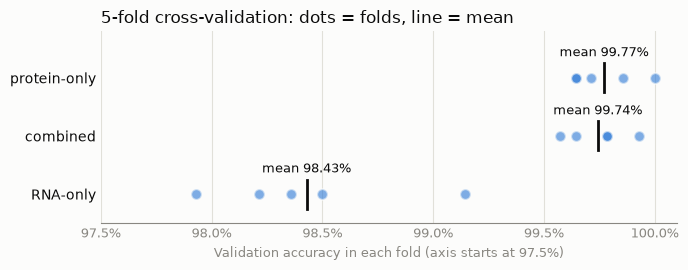

In [39]:
# models from top to bottom
model_order = ["protein-only", "combined", "RNA-only"]

figure, axis = plt.subplots(figsize=(7, 2.8))
figure.patch.set_facecolor(surface_color)
axis.set_facecolor(surface_color)

for position in range(len(model_order)):
    model_name = model_order[position]
    model_rows = cv_results[cv_results["model"] == model_name]

    # one dot per fold
    fold_accuracies = model_rows["accuracy"].values
    axis.scatter(fold_accuracies, [position] * len(fold_accuracies), s=60, color=highlight_color, alpha=0.6, edgecolors=surface_color, linewidths=1.5, zorder=3)

    # a short dark line at the mean, with its value
    mean_accuracy = fold_accuracies.mean()
    axis.plot([mean_accuracy, mean_accuracy], [position - 0.25, position + 0.25], color=text_color, linewidth=2, zorder=4)
    label = "mean " + str(round(mean_accuracy * 100, 2)) + "%"
    axis.text(mean_accuracy, position - 0.32, label, ha="center", va="bottom", fontsize=9, color=text_color)

# label the rows, first model on top
axis.set_yticks(range(len(model_order)))
axis.set_yticklabels(model_order, fontsize=10, color=text_color)
axis.set_ylim(len(model_order) - 0.5, -0.8)

# percent axis
axis.set_xlim(0.975, 1.001)
tick_values = [0.975, 0.98, 0.985, 0.99, 0.995, 1.0]
tick_labels = []
for tick in tick_values:
    tick_labels.append(str(round(tick * 100, 1)) + "%")
axis.set_xticks(tick_values)
axis.set_xticklabels(tick_labels, fontsize=9, color=muted_color)
axis.set_xlabel("Validation accuracy in each fold (axis starts at 97.5%)", fontsize=9, color=muted_color)

# light vertical grid, no box
axis.grid(axis="x", color=grid_color, linewidth=0.8)
axis.set_axisbelow(True)
for side in ["top", "right", "left"]:
    axis.spines[side].set_visible(False)
axis.spines["bottom"].set_color(muted_color)
axis.tick_params(axis="both", length=0)

axis.set_title("5-fold cross-validation: dots = folds, line = mean", loc="left", fontsize=12, color=text_color)
plt.tight_layout()
plt.show()

### Trying different regularization strengths (C)

Logistic regression already uses L2 regularization. We try the same 5 values for all three models, with the same 5 folds as above, and pick each model's best C by its mean cross-validation accuracy.


In [ ]:
c_values = [0.001, 0.01, 0.1, 1.0, 10.0]

# one row per model per C per fold
c_rows = []
for c_value in c_values:
    fold_number = 0
    for cv_train_rows, cv_valid_rows in folds.split(all_protein, cell_types):
        fold_number = fold_number + 1

        # train and score each model on this fold
        for model_name in feature_sets:
            features = feature_sets[model_name]
            accuracy, macro_f1, wrong = fit_and_score(
                features[cv_train_rows],
                cell_types[cv_train_rows],
                features[cv_valid_rows],
                cell_types[cv_valid_rows],
                c_value=c_value,
            )
            c_rows.append({
                "model": model_name,
                "C": c_value,
                "fold": fold_number,
                "accuracy": accuracy,
                "macro F1": macro_f1,
                "wrong cells": wrong,
            })

    print("finished C =", c_value)

# turn the results into a table
c_results = pd.DataFrame(c_rows)

finished C = 0.001
finished C = 0.01
finished C = 0.1
finished C = 1.0
finished C = 10.0


In [41]:
# mean accuracy for each model and C (rows = C, columns = model)
c_accuracy_table = c_results.pivot_table(index="C", columns="model", values="accuracy", aggfunc="mean")

# mean wrong cells for each model and C
c_wrong_table = c_results.pivot_table(index="C", columns="model", values="wrong cells", aggfunc="mean")

print("mean accuracy:")
print(c_accuracy_table.round(4))
print()
print("mean wrong cells (out of 1,400):")
print(c_wrong_table.round(1))

mean accuracy:
model   RNA-only  combined  protein-only
C                                       
0.001     0.9803    0.9960        0.9970
0.010     0.9846    0.9971        0.9976
0.100     0.9854    0.9973        0.9980
1.000     0.9843    0.9974        0.9977
10.000    0.9846    0.9976        0.9976

mean wrong cells (out of 1,400):
model   RNA-only  combined  protein-only
C                                       
0.001       27.6       5.6           4.2
0.010       21.6       4.0           3.4
0.100       20.4       3.8           2.8
1.000       22.0       3.6           3.2
10.000      21.6       3.4           3.4


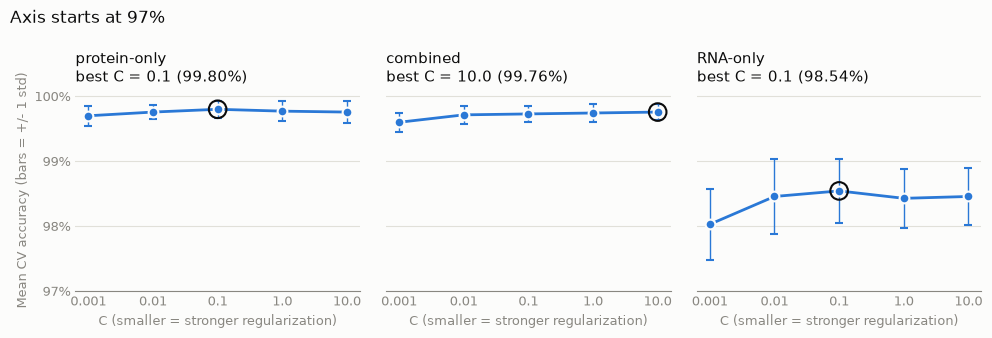

In [47]:
# models from left to right
model_order = ["protein-only", "combined", "RNA-only"]

figure, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
figure.patch.set_facecolor(surface_color)

for panel in range(len(model_order)):
    model_name = model_order[panel]
    axis = axes[panel]
    axis.set_facecolor(surface_color)

    # mean and spread of accuracy for each C
    mean_accuracies = []
    spread_accuracies = []
    for c_value in c_values:
        rows = c_results[(c_results["model"] == model_name) & (c_results["C"] == c_value)]
        mean_accuracies.append(rows["accuracy"].mean())
        spread_accuracies.append(rows["accuracy"].std())

    # positions 0, 1, 2, ... so the C values are evenly spaced
    positions = list(range(len(c_values)))

    # mean line with thin bars for the spread across folds
    axis.errorbar(positions, mean_accuracies, yerr=spread_accuracies, color=highlight_color, linewidth=2, elinewidth=1, capsize=3, marker="o", markersize=7, markeredgecolor=surface_color, markeredgewidth=1.5, zorder=3)

    # ring the best C
    best_position = int(np.argmax(mean_accuracies))
    best_value = mean_accuracies[best_position]
    axis.scatter([best_position], [best_value], s=160, facecolors="none", edgecolors=text_color, linewidths=1.5, zorder=4)

    # x axis shows the C values
    axis.set_xticks(positions)
    c_labels = []
    for c_value in c_values:
        c_labels.append(str(c_value))
    axis.set_xticklabels(c_labels, fontsize=9, color=muted_color)
    axis.set_xlabel("C (smaller = stronger regularization)", fontsize=9, color=muted_color)

    # light horizontal grid, no box
    axis.grid(axis="y", color=grid_color, linewidth=0.8)
    axis.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        axis.spines[side].set_visible(False)
    axis.spines["bottom"].set_color(muted_color)
    axis.tick_params(axis="both", length=0)

    # name the model and its best C in the panel title
    best_text = "best C = " + str(c_values[best_position]) + " (" + format(best_value * 100, ".2f") + "%)"
    axis.set_title(model_name + "\n" + best_text, loc="left", fontsize=11, color=text_color)

# shared percent axis
axes[0].set_ylim(0.97, 1.001)
tick_values = [0.97, 0.98, 0.99, 1.0]
tick_labels = []
for tick in tick_values:
    tick_labels.append(str(round(tick * 100)) + "%")
axes[0].set_yticks(tick_values)
axes[0].set_yticklabels(tick_labels, fontsize=9, color=muted_color)
axes[0].set_ylabel("Mean CV accuracy (bars = +/- 1 std)", fontsize=9, color=muted_color)

figure.suptitle("Axis starts at 97%", x=0.01, ha="left", fontsize=12, color=text_color)
plt.tight_layout()
plt.show()

### Final submission

We chose **protein-only with C = 0.1**. In cross-validation it tied with the combined model, and it is simpler (217 features instead of 3,217).

Now that we made our decision, we retrain it on all 7,000 training cells and predict both test sets

In [43]:
import os

# best C for protein-only from cross-validation
final_c_value = 0.1

# fit the scaler on all 7,000 training cells
final_scaler = StandardScaler()
final_scaler.fit(protein)
all_protein_scaled = final_scaler.transform(protein)

# train the final model on all 7,000 training cells
final_model = LogisticRegression(C=final_c_value, max_iter=1000, random_state=42)
final_model.fit(all_protein_scaled, cell_types)

print("trained on", all_protein_scaled.shape[0], "cells")

trained on 7000 cells


In [44]:
from sklearn.preprocessing import LabelEncoder

# scale both test sets with the scaler fit on the 7,000 training cells
test1_protein_scaled = final_scaler.transform(test1_protein[protein.columns])
test2_protein_scaled = final_scaler.transform(test2_protein[protein.columns])

# predict a cell type name for each test cell
test1_predictions = final_model.predict(test1_protein_scaled)
test2_predictions = final_model.predict(test2_protein_scaled)

# turn the names into numbers 0-4 (alphabetical order)
label_encoder = LabelEncoder()
label_encoder.fit(cell_types)
print("label order:", label_encoder.classes_)
test1_numbers = label_encoder.transform(test1_predictions)
test2_numbers = label_encoder.transform(test2_predictions)

# one table per test set, in the same order as its cells.csv
test1_submission = pd.DataFrame({"ID": test1_cells["cell_id"].values, "label": test1_numbers})
test2_submission = pd.DataFrame({"ID": test2_cells["cell_id"].values, "label": test2_numbers})

# stack test1 on top of test2
submission = pd.concat([test1_submission, test2_submission], ignore_index=True)
print(submission.shape)

label order: ['B' 'CD4 T' 'CD8 T' 'Mono' 'NK']
(3000, 2)


In [45]:
# the label order must be exactly B, CD4 T, CD8 T, Mono, NK = 0-4
expected_order = ["B", "CD4 T", "CD8 T", "Mono", "NK"]
print("label order is correct:", list(label_encoder.classes_) == expected_order)

# check the submission matches the sample format
print("same columns:", list(submission.columns) == list(sample_submission.columns))
print("same number of rows:", len(submission) == len(sample_submission))
print("same IDs in the same order:", (submission["ID"].values == sample_submission["ID"].values).all())
print("no duplicated IDs:", submission["ID"].duplicated().sum() == 0)
print("no missing labels:", submission["label"].notna().all())
print("every label is 0-4:", submission["label"].isin([0, 1, 2, 3, 4]).all())
print()

# share of each predicted label in each test set (a sanity check only, not for tuning)
print("test1:")
print(test1_submission["label"].value_counts(normalize=True).sort_index().round(3))
print("test2:")
print(test2_submission["label"].value_counts(normalize=True).sort_index().round(3))
submission.head()

label order is correct: True
same columns: True
same number of rows: True
same IDs in the same order: True
no duplicated IDs: True
no missing labels: True
every label is 0-4: True

test1:
label
0    0.094
1    0.288
2    0.173
3    0.337
4    0.109
Name: proportion, dtype: float64
test2:
label
0    0.094
1    0.288
2    0.175
3    0.334
4    0.109
Name: proportion, dtype: float64


,ID,label
0,E2L6_ACACTGAGTCTGCATA,3
1,L4_CCGGTGAAGTAGTCCT,3
2,L1_ACGTCCTAGTCCCTAA,0
3,E2L6_CATCAAGTCGAATGCT,3
4,L5_CCTCTAGTCGACCTAA,1


In [46]:
# make the results folder if it does not exist yet
results_folder = "../results"
os.makedirs(results_folder, exist_ok=True)

# save the submission without the row numbers, named after the model
submission_path = os.path.join(results_folder, "submission_protein_logreg.csv")
submission.to_csv(submission_path, index=False)

print("saved to", submission_path)

saved to ../results\submission_protein_logreg.csv
